In [9]:
import pandas as pd
import openpyxl

df_sectorwise = pd.read_excel("dataset_project_sectorwise.xlsx", engine='openpyxl')
df_sectorwise

,Entity,Code,Year,Buildings,industry,land-use change and forestry,other fuel combustion,transport,manufacturing and construction,energy production,electricity and heat,bunker fuels
0,United States,USA,1990,545480000,33480000.0,-408780000,66320000.0,1426970000,604440000,7880000.0,2159790000,130820010.0
1,United States,USA,1991,555179970,32740002.0,-408780000,64050004.0,1399670000,566880000,8890000.0,2179910000,137090000.0
2,United States,USA,1992,565060000,32990002.0,-408780000,47370000.0,1430660100,517640000,8770000.0,2276970000,143980000.0
3,United States,USA,1993,585570000,34840000.0,-408930000,45000000.0,1454190000,532419970,7520000.0,2335520000,132470000.0
4,United States,USA,1994,575850000,36310000.0,-409080000,45770000.0,1506900000,534850000,6300000.0,2360700000,130170000.0
...,...,...,...,...,...,...,...,...,...,...,...,...
193,Brazil,BRA,2018,20420000,20560000.0,384480000,18780000.0,191870000,88360000,1980000.0,91210000,16740000.0
194,Brazil,BRA,2019,20370000,20840000.0,384470000,19120000.0,193170000,84810000,2210000.0,90330000,17960000.0
195,Brazil,BRA,2020,20860000,23840000.0,384470000,19420000.0,182610000,78540000,1940000.0,84580000,14970000.0
196,Brazil,BRA,2021,20580000,25290000.0,384480000,19530000.0,200170000,88560000,1770000.0,110290000,13040000.0


In [10]:
print(df_sectorwise.columns.tolist())


['Entity', 'Code', 'Year', ' Buildings', ' industry', ' land-use change and forestry', ' other fuel combustion', ' transport', ' manufacturing and construction', ' energy production', ' electricity and heat', ' bunker fuels']


In [11]:
df_sectorwise.isna().sum()


Entity                              0
Code                                0
Year                                0
 Buildings                          0
 industry                           0
 land-use change and forestry       0
 other fuel combustion              0
 transport                          0
 manufacturing and construction     0
 energy production                 37
 electricity and heat               0
 bunker fuels                       0
dtype: int64

In [12]:
df_sectorwise_clean = df_sectorwise.dropna()


In [13]:
df_sectorwise['Year'].min(), df_sectorwise['Year'].max()


(1990, 2022)

In [14]:
# 1. Select only numeric columns
numeric_cols = df_sectorwise.select_dtypes(include=['number']).columns

# 2a. Remove rows where any numeric value is negative
df_clean = df_sectorwise[(df_sectorwise[numeric_cols] >= 0).all(axis=1)]

# 2b. Alternatively, replace negative numeric values with 0
df_sectorwise[numeric_cols] = df_sectorwise[numeric_cols].clip(lower=0)



In [15]:
df_sectorwise.info()
df_sectorwise.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Entity                           198 non-null    object 
 1   Code                             198 non-null    object 
 2   Year                             198 non-null    int64  
 3    Buildings                       198 non-null    int64  
 4    industry                        198 non-null    float64
 5    land-use change and forestry    198 non-null    int64  
 6    other fuel combustion           198 non-null    float64
 7    transport                       198 non-null    int64  
 8    manufacturing and construction  198 non-null    int64  
 9    energy production               161 non-null    float64
 10   electricity and heat            198 non-null    int64  
 11   bunker fuels                    198 non-null    float64
dtypes: float64(4), int64(6

,Year,Buildings,industry,land-use change and forestry,other fuel combustion,transport,manufacturing and construction,energy production,electricity and heat,bunker fuels
count,198.000000,1.980000e+02,1.980000e+02,1.980000e+02,1.980000e+02,1.980000e+02,1.980000e+02,1.610000e+02,1.980000e+02,1.980000e+02
mean,2006.000000,2.006219e+08,8.987313e+07,1.335331e+08,4.005515e+07,4.288578e+08,4.372219e+08,3.912050e+06,1.001760e+09,3.871788e+07
std,9.546041,2.078580e+08,1.960616e+08,3.329736e+08,5.468686e+07,5.815493e+08,7.684974e+08,4.970484e+06,1.463375e+09,4.555131e+07
min,1990.000000,9.600000e+05,5.900000e+05,0.000000e+00,5.200000e+05,1.003000e+07,4.550000e+06,0.000000e+00,6.970000e+06,1.430000e+06
25%,1998.000000,2.012500e+07,8.470000e+06,0.000000e+00,7.280000e+06,1.205125e+08,5.155000e+07,1.330000e+06,5.285750e+07,1.093000e+07
50%,2006.000000,1.045750e+08,1.441500e+07,0.000000e+00,1.446500e+07,1.486150e+08,9.358500e+07,2.380000e+06,1.765800e+08,2.220000e+07
75%,2014.000000,3.839075e+08,3.945500e+07,0.000000e+00,4.726500e+07,4.254350e+08,4.833975e+08,4.520000e+06,1.938480e+09,3.469250e+07
max,2022.000000,6.163700e+08,8.287000e+08,1.101280e+09,2.020300e+08,1.807720e+09,3.060040e+09,3.165000e+07,6.447730e+09,1.680900e+08


In [16]:
print(df_sectorwise["Entity"].value_counts())


Entity
United States    33
Germany          33
France           33
Norway           33
China            33
Brazil           33
Name: count, dtype: int64


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [18]:
# Load dataset
df = pd.read_csv("dataset_project_sectorwise.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Rename for clarity
df = df.rename(columns={"entity": "country"})


In [19]:
df.columns

Index(['country', 'code', 'year', 'buildings', 'industry',
       'land-use change and forestry', 'other fuel combustion', 'transport',
       'manufacturing and construction', 'energy production',
       'electricity and heat', 'bunker fuels'],
      dtype='object')

In [20]:
sector_cols = [
    "buildings",
    "industry",
    "transport",
    "manufacturing and construction",
    "energy production",
    "electricity and heat",
    "other fuel combustion",
    "land-use change and forestry",
    "bunker fuels"
]


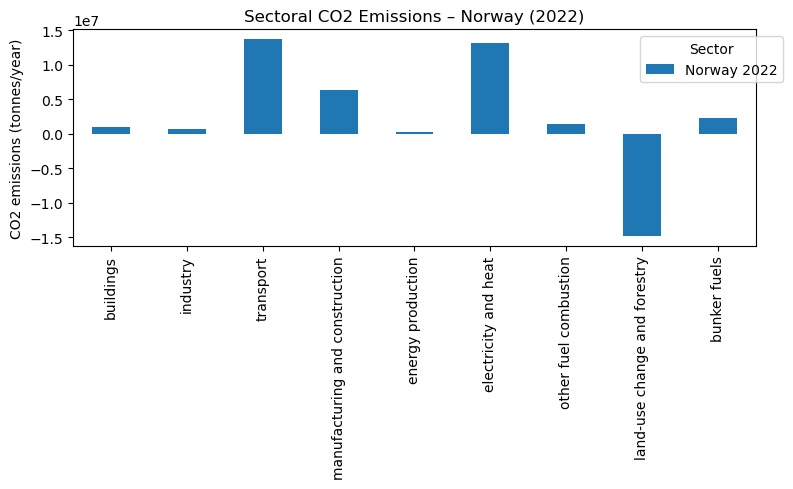

In [21]:
country = "Norway"
year = 2022

df_country = df[(df["country"] == country) & (df["year"] == year)]

df_plot = df_country[sector_cols].T
df_plot.columns = ["Norway 2022"]

df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.ylabel("CO2 emissions (tonnes/year)")
plt.title(f"Sectoral CO2 Emissions – {country} ({year})")
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()



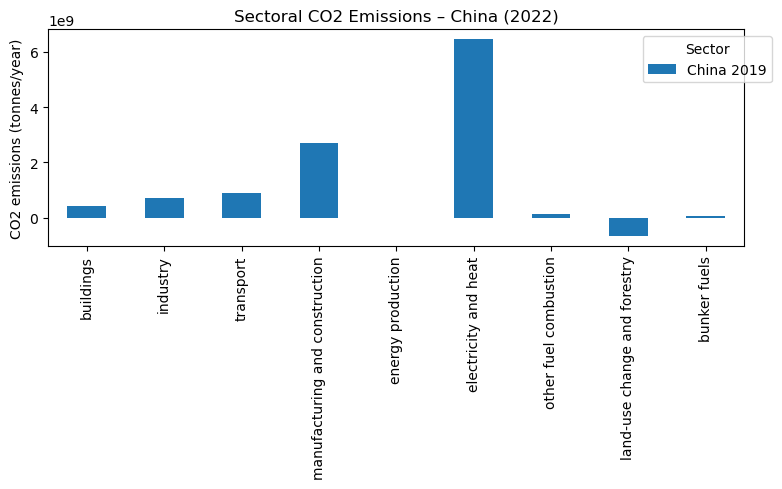

In [22]:
country = "China"
year = 2022

df_country = df[(df["country"] == country) & (df["year"] == year)]

df_plot = df_country[sector_cols].T
df_plot.columns = ["China 2019"]

df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.ylabel("CO2 emissions (tonnes/year)")
plt.title(f"Sectoral CO2 Emissions – {country} ({year})")
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [23]:
countries = ["Norway", "Germany"]
year = 2022

df_compare = df[
    (df["country"].isin(countries)) &
    (df["year"] == year)
].copy()



In [24]:
df_compare[["country", "year"]]


,country,year
65,Germany,2022
131,Norway,2022


In [25]:
df_compare = df_compare.set_index("country")[sector_cols]


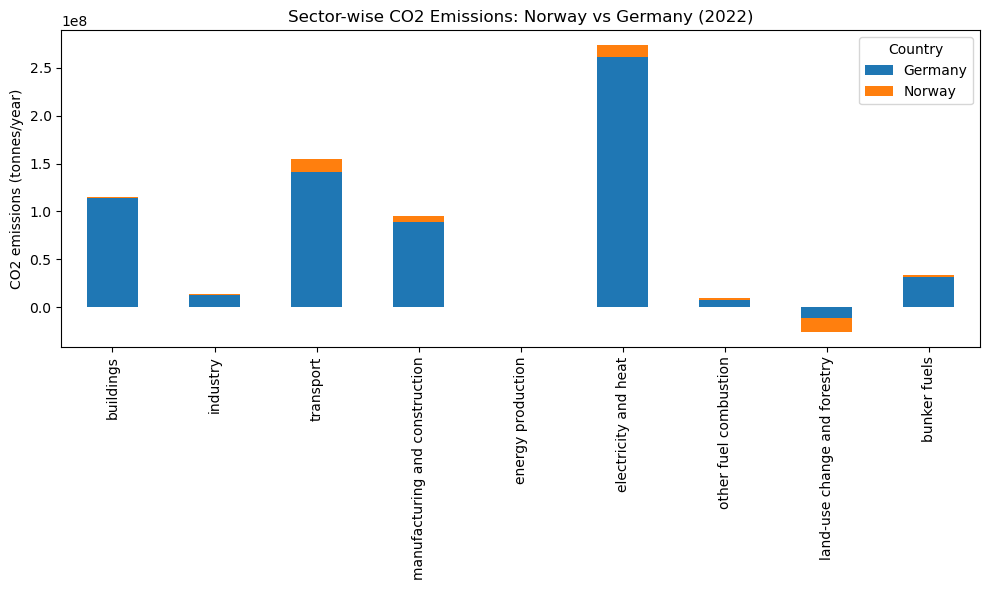

In [26]:
import matplotlib.pyplot as plt

df_compare.T.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.ylabel("CO2 emissions (tonnes/year)")
plt.title("Sector-wise CO2 Emissions: Norway vs Germany (2022)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()


This graph compares sector-wise CO₂ emissions of Germany and Norway in 2022. Germany emits much more CO₂ than Norway in almost all sectors, especially in electricity and heat production, which is the largest contributor due to fossil-fuel-based power generation. Emissions from transport and manufacturing are also significantly higher in Germany because of its large industrial and transport sectors. Norway shows much lower emissions in electricity and buildings because its power system is mainly based on hydropower. Transport remains an important emission source for Norway, but overall emissions are smaller. Land-use change and forestry in Norway show negative emissions, meaning forests absorb CO₂, which further reduces its total emissions compared to Germany.

In [27]:
import matplotlib.pyplot as plt

sector_cols = [
    "buildings",
    "industry",
    "transport",
    "manufacturing and construction",
    "energy production",
    "electricity and heat",
    "other fuel combustion",
    "bunker fuels",
    "land-use change and forestry"
]

country = "Germany"

df_country = df[df["country"] == country].sort_values("year")



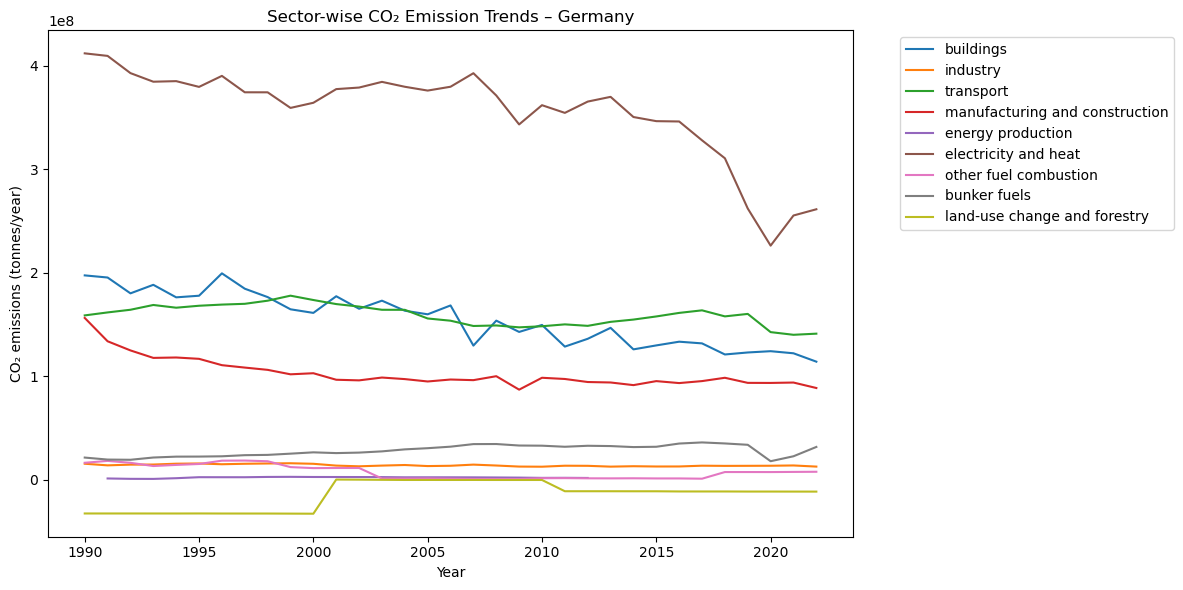

In [28]:
plt.figure(figsize=(12, 6))

for sector in sector_cols:
    plt.plot(
        df_country["year"],
        df_country[sector],
        label=sector
    )

plt.xlabel("Year")
plt.ylabel("CO₂ emissions (tonnes/year)")
plt.title(f"Sector-wise CO₂ Emission Trends – {country}")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [29]:
import matplotlib.pyplot as plt

sector_cols = [
    "buildings",
    "industry",
    "transport",
    "manufacturing and construction",
    "energy production",
    "electricity and heat",
    "other fuel combustion",
    "bunker fuels",
    "land-use change and forestry"
]

country = "China"

df_country = df[df["country"] == country].sort_values("year")


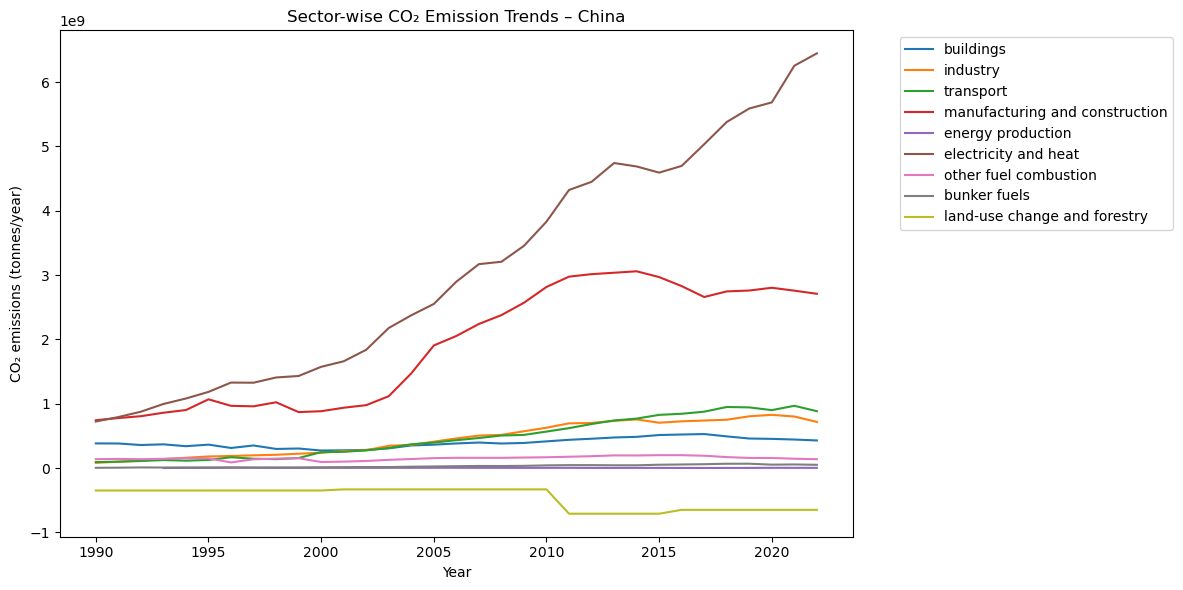

In [30]:
plt.figure(figsize=(12, 6))

for sector in sector_cols:
    plt.plot(
        df_country["year"],
        df_country[sector],
        label=sector
    )

plt.xlabel("Year")
plt.ylabel("CO₂ emissions (tonnes/year)")
plt.title("Sector-wise CO₂ Emission Trends – China")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [31]:
countries = ["Norway", "Germany", "China", "United States", "France", "Brazil"]
year = 2022

df_plot = df[
    (df["country"].isin(countries)) &
    (df["year"] == year)
].copy()


In [32]:
df_plot = df_plot.set_index("country")[sector_cols]


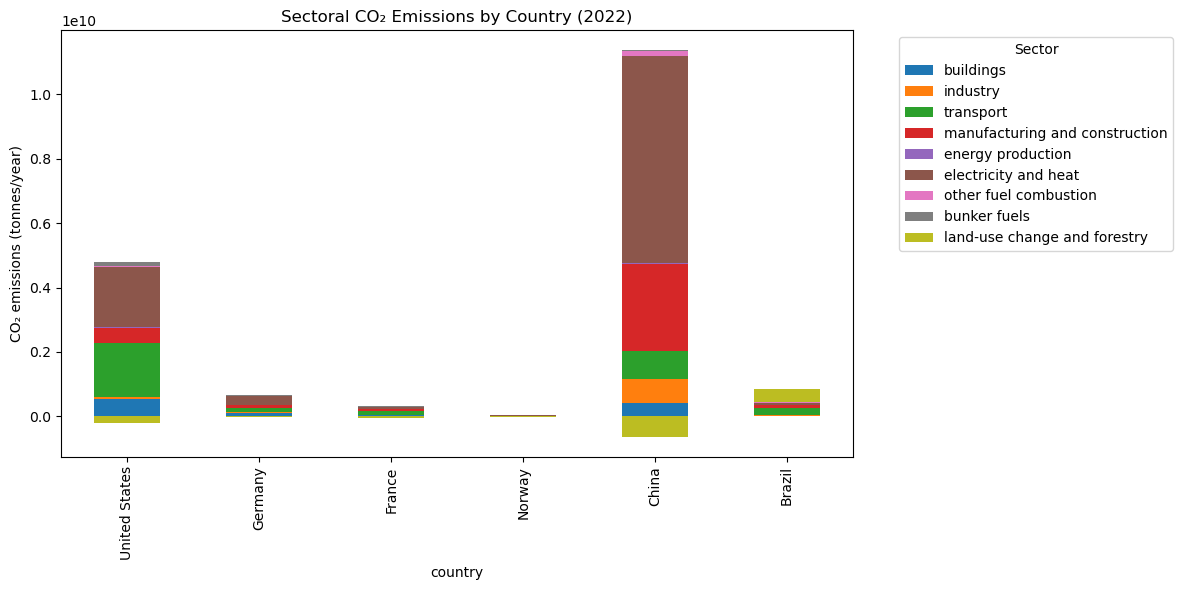

In [33]:
import matplotlib.pyplot as plt

df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.ylabel("CO₂ emissions (tonnes/year)")
plt.title("Sectoral CO₂ Emissions by Country (2022)")
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [ ]:
df["total_co2"] = df[sector_cols].sum(axis=1)


In [ ]:
corr_data = df[sector_cols + ["total_co2"]].corr()


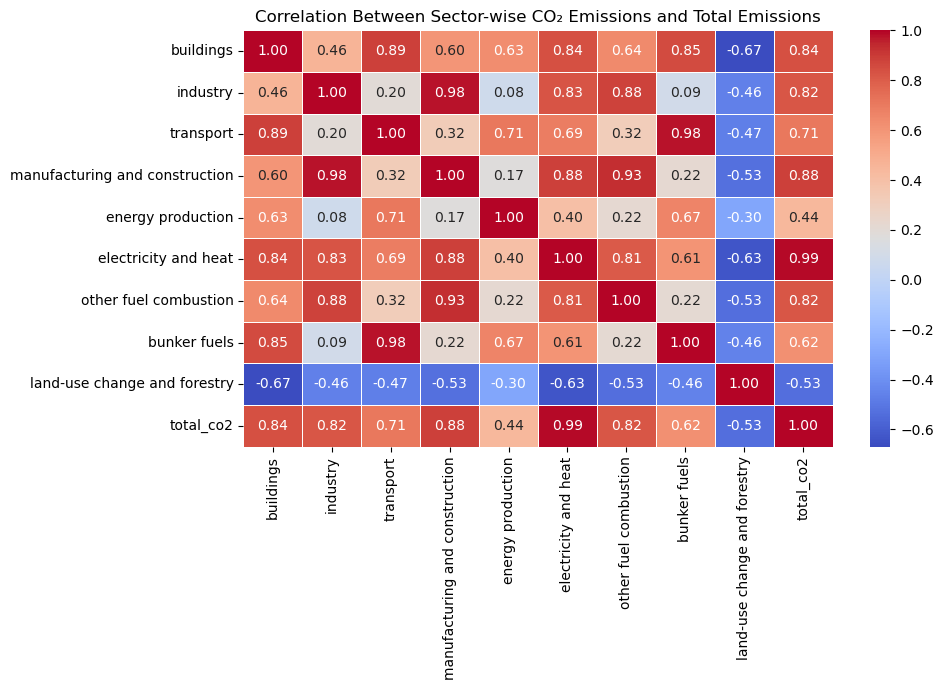

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Sector-wise CO₂ Emissions and Total Emissions")
plt.tight_layout()
plt.show()
